# Practical 2 · Logistic regression, step by step (customer churn)

**Goal:** predict which customers will **leave** (churn) a telecom company, so the retention team can call them first.

This is **classification** (the answer is yes/no). We follow the same recipe as Practical 1 (same step numbers as Part 3), and add the new parts classification needs: probabilities, the confusion matrix, precision and recall, and choosing a threshold.

## Step 0 · Set up the tools

In [1]:
import os
from urllib.request import urlretrieve
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings; warnings.filterwarnings('ignore')
sns.set_style('whitegrid'); plt.rcParams['figure.figsize'] = (8, 4.5)
print('Tools ready')

Tools ready


## Step 1 · Load the data

In [2]:
url = 'https://raw.githubusercontent.com/MusaBangash/Python-Variables/main/ml/data/telco-churn.csv'
if not os.path.exists('telco-churn.csv'):
    urlretrieve(url, 'telco-churn.csv')
df = pd.read_csv('telco-churn.csv')
print(df.shape)
df.head(3)

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


One row = one customer, 21 columns. `Churn` (Yes/No) is what we predict.

## Step 2 · First look

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

**Something is odd:** `TotalCharges` is money, but its type is text (`object`/`str`), not a number. That means some cells contain something that isn't a number. Let's find them before converting.

## Step 4 · Check data quality (and fix TotalCharges)

In [4]:
as_number = pd.to_numeric(df['TotalCharges'], errors='coerce')   # cells that aren't numbers become NaN
bad = as_number.isna()
print('Cells that are not numbers:', bad.sum())
df.loc[bad, ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges']]

Cells that are not numbers: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


All 11 are **blank**, and every one has **tenure = 0**: brand-new customers who haven't received a bill yet. So the true total paid is **0**, not "the average". We fill with 0. (Always ask *why* a value is missing before filling it.)

In [5]:
df['TotalCharges'] = as_number.fillna(0)
print('Missing values now:', df.isna().sum().sum())
print('Duplicate customer IDs:', df['customerID'].duplicated().sum())
print('Rows identical apart from the ID:', df.drop(columns='customerID').duplicated().sum())

Missing values now: 0
Duplicate customer IDs: 0
Rows identical apart from the ID: 22


The 22 look-alike rows have **different** customer IDs: different people with the same simple profile. They are real customers, so we keep them. (In Practical 1 the duplicate was the *same* record twice.)

## Step 3 · Target, features and task type

In [6]:
df['Churn'] = (df['Churn'] == 'Yes').astype(int)       # 1 = left, 0 = stayed
X = df.drop(columns=['customerID', 'Churn'])           # drop the ID (a name tag) and the target
y = df['Churn']
print('Classification: target is 0/1')
print(y.value_counts())
print('Churn rate:', round(y.mean(), 3))

Classification: target is 0/1
Churn
0    5174
1    1869
Name: count, dtype: int64
Churn rate: 0.265


**Only 26.5% churn.** This is an **imbalanced** target. A model that always says "stays" is already 73.5% accurate, and completely useless. Remember this when you see accuracy numbers.

## Step 6 · Split (stratified)
`stratify=y` keeps the churn rate the same (26.5%) in training and test sets.

In [7]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print('Train:', X_train.shape, 'churn rate', round(y_train.mean(), 3))
print('Test: ', X_test.shape, 'churn rate', round(y_test.mean(), 3))

Train: (5634, 19) churn rate 0.265
Test:  (1409, 19) churn rate 0.265


## Step 5 · Explore (training data only)

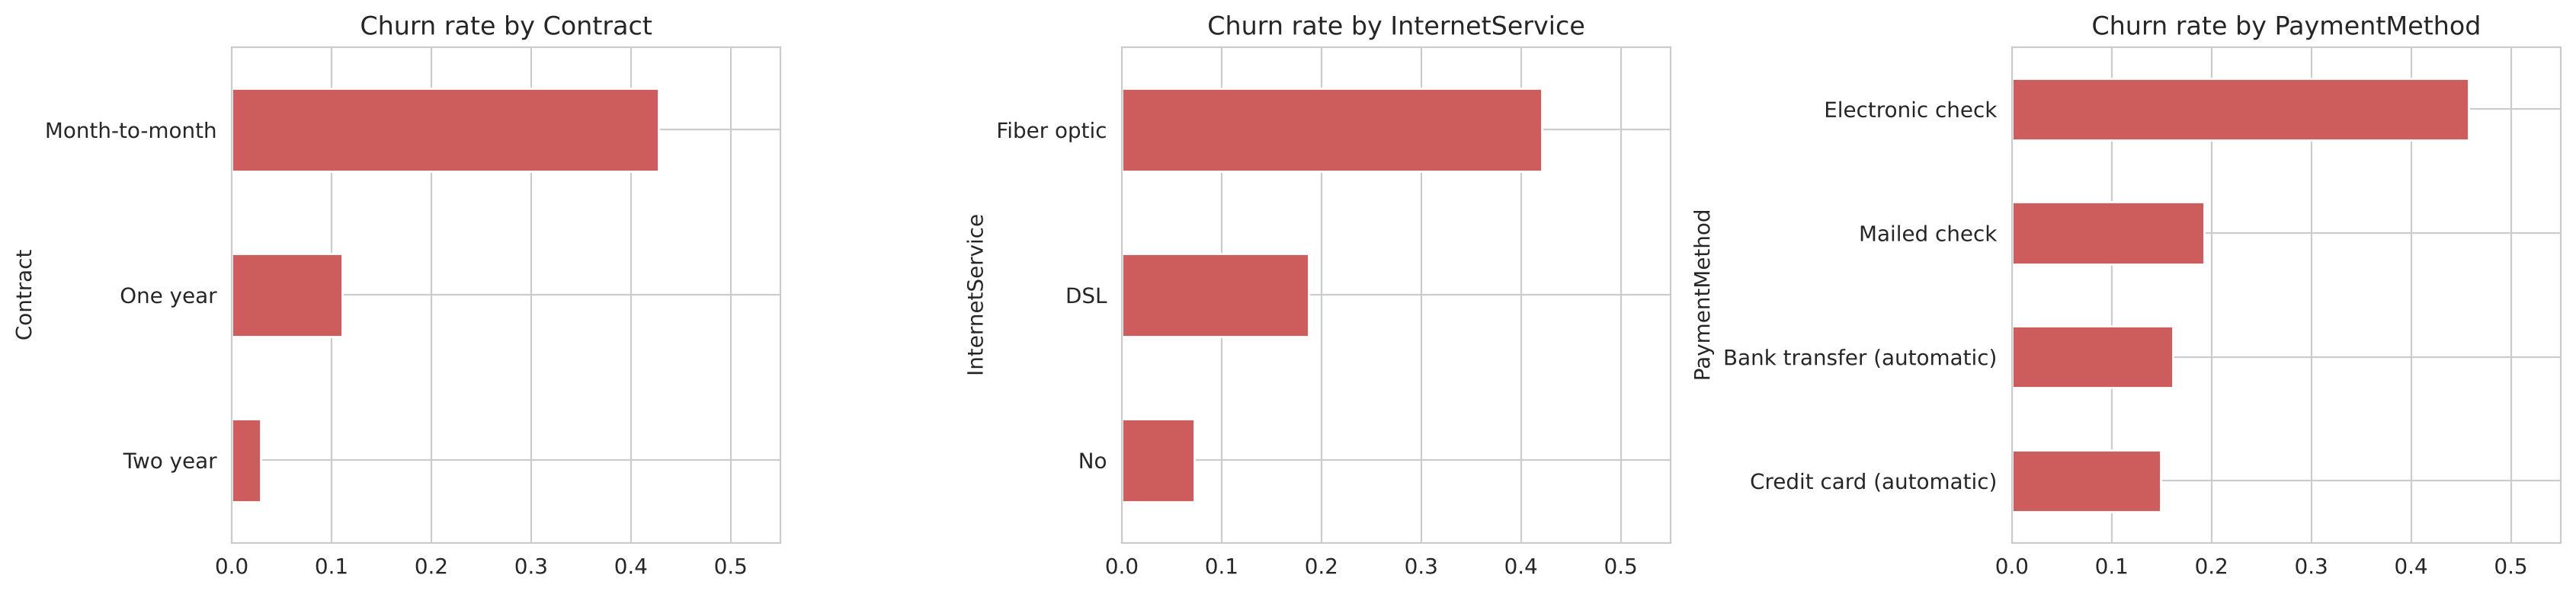

In [8]:
train = X_train.assign(Churn=y_train)
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, col in zip(axes, ['Contract', 'InternetService', 'PaymentMethod']):
    train.groupby(col)['Churn'].mean().sort_values().plot.barh(ax=ax, color='indianred')
    ax.set_title(f'Churn rate by {col}'); ax.set_xlim(0, .55)
plt.tight_layout(); plt.show()

- **Contract:** month-to-month customers leave far more (~43%) than two-year customers (~3%).
- **Fiber internet** customers leave about twice as often as DSL customers.
- Customers paying by **electronic check** leave most.

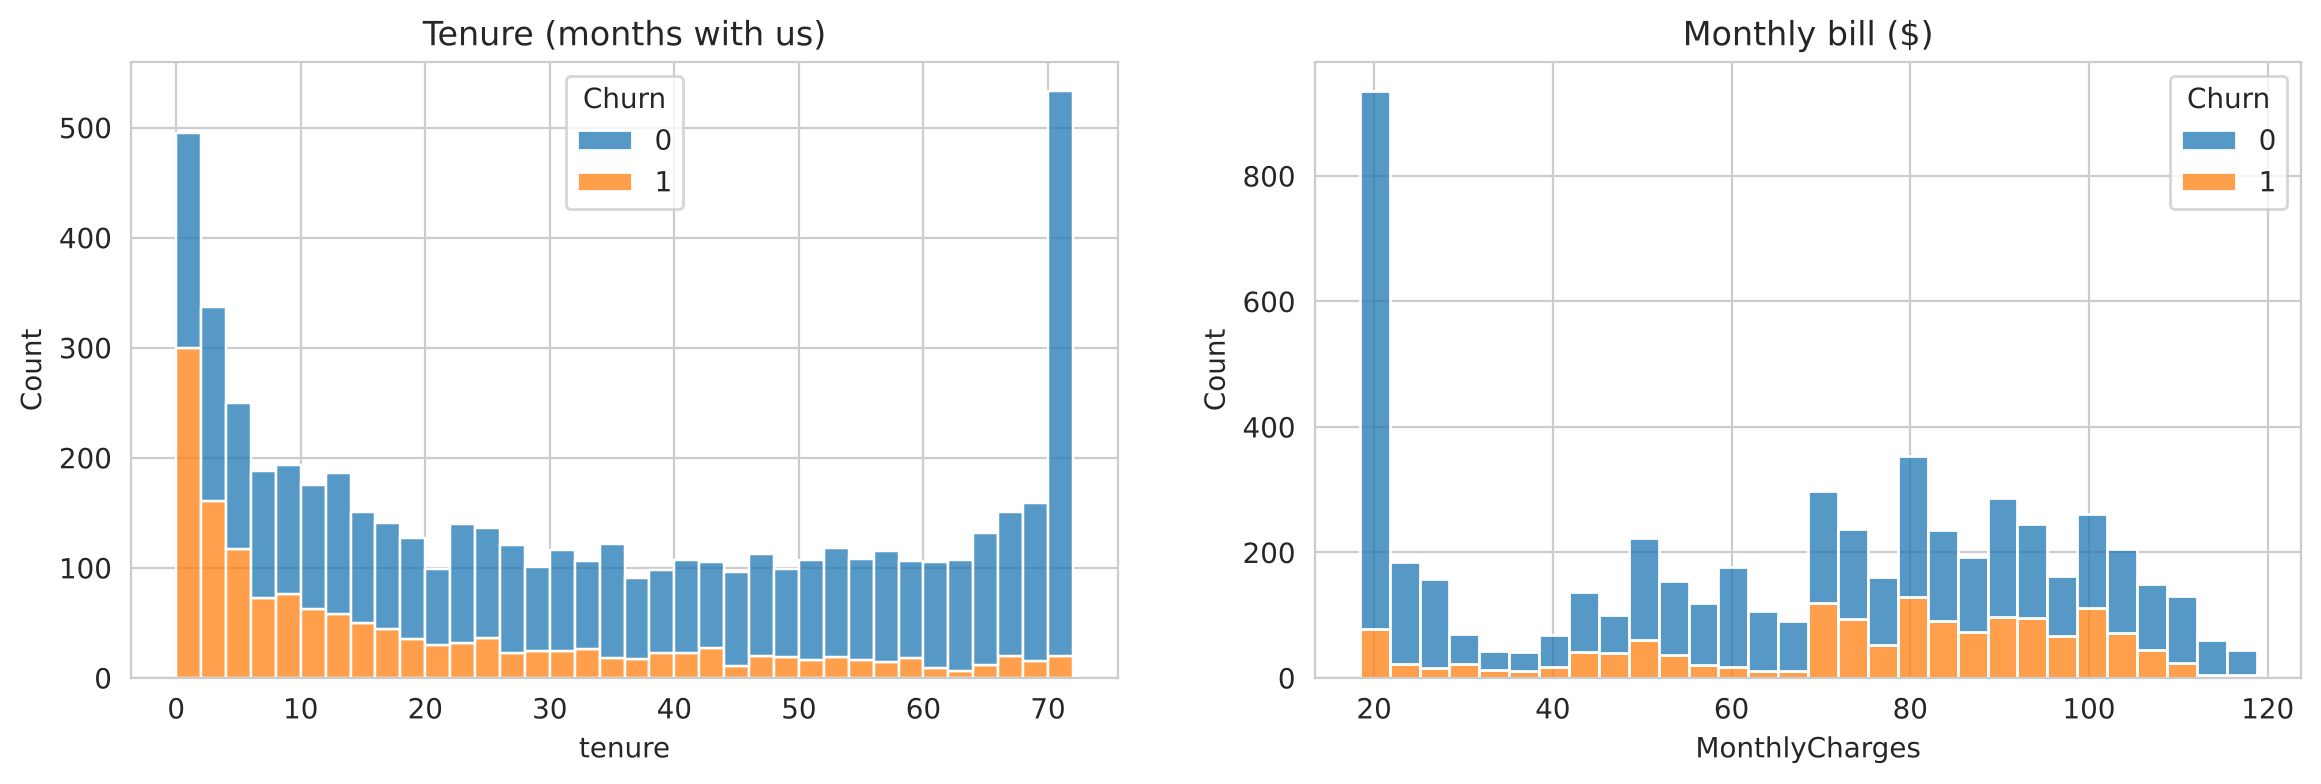

,tenure,MonthlyCharges
Churn,,
0,38.0,64.40
1,10.0,79.95


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=train, x='tenure', hue='Churn', bins=36, multiple='stack', ax=ax[0]); ax[0].set_title('Tenure (months with us)')
sns.histplot(data=train, x='MonthlyCharges', hue='Churn', bins=30, multiple='stack', ax=ax[1]); ax[1].set_title('Monthly bill ($)')
plt.show()
train.groupby('Churn')[['tenure', 'MonthlyCharges']].median()

Leavers are mostly **new** (median 10 months vs 38) and pay **more** each month. Risk is highest in the first year.

## Step 7 · Feature types

In [10]:
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']
categorical_cols = [c for c in X.columns if c not in numeric_cols]
print(len(numeric_cols), 'numeric:', numeric_cols)
print(len(categorical_cols), 'categorical:', categorical_cols)

4 numeric: ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']
15 categorical: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## Steps 8, 9, 10, 12 · Missing values, encoding, scaling, all in one pipeline

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

preprocess = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), numeric_cols),
    ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), categorical_cols),
])
logreg = Pipeline([('preprocess', preprocess), ('model', LogisticRegression(max_iter=2000))])
print('Columns after preprocessing:', preprocess.fit(X_train).transform(X_train.head()).shape[1])

Columns after preprocessing: 45


19 raw columns become 45 after one-hot encoding (each category gets its own 0/1 column).

## Step 13 · Baselines, and the accuracy trap
We score with several metrics using 5-fold **stratified** cross-validation:
- **accuracy:** % correct
- **precision:** of the customers we flag, how many really leave
- **recall:** of the customers who really leave, how many we flag
- **F1:** a balance of precision and recall
- **ROC AUC:** how well the model ranks leavers above stayers (0.5 = random, 1 = perfect)

In [12]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = {}
def evaluate(name, model):
    cv = cross_validate(model, X_train, y_train, cv=folds, scoring=('accuracy', 'precision', 'recall', 'f1', 'roc_auc'))
    results[name] = {m: cv[f'test_{m}'].mean() for m in ('accuracy', 'precision', 'recall', 'f1', 'roc_auc')}
    return pd.DataFrame(results).T.round(3)

evaluate('Baseline: always "stays"', DummyClassifier(strategy='most_frequent'))

,accuracy,precision,recall,f1,roc_auc
"Baseline: always ""stays""",0.735,0.0,0.0,0.0,0.5


**73.5% accuracy, 0 recall:** it never finds a single leaver. Accuracy alone lies on imbalanced data.

## Step 15 · Train logistic regression

In [13]:
evaluate('Logistic regression', logreg)

,accuracy,precision,recall,f1,roc_auc
"Baseline: always ""stays""",0.735,0.000,0.000,0.000,0.500
Logistic regression,0.802,0.653,0.543,0.592,0.846


Accuracy rises to ~80%, but look at **recall ≈ 0.54**: we find only about half of the leavers. **Precision ≈ 0.66**: two in three flagged customers really leave. ROC AUC ≈ 0.85 means the **ranking** is good. The problem is the default **threshold**, which we fix in Step 16c.

## Step 16 · Evaluate
### 16a · Probabilities, not just yes/no
Logistic regression outputs a **probability** of leaving. The default rule says "leaves" when probability ≥ 0.5. We get honest probabilities for every training customer with `cross_val_predict` (each customer is predicted by a model that didn't train on them).

In [14]:
from sklearn.model_selection import cross_val_predict
proba = cross_val_predict(logreg, X_train, y_train, cv=folds, method='predict_proba')[:, 1]
pd.DataFrame({'actual (1 = left)': y_train.values[:8], 'probability of leaving': proba[:8].round(3),
              'prediction at 0.5': (proba[:8] >= 0.5).astype(int)})

,actual (1 = left),probability of leaving,prediction at 0.5
0,0,0.378,0
1,0,0.294,0
2,0,0.040,0
3,0,0.090,0
4,0,0.370,0
5,0,0.015,0
6,0,0.167,0
7,0,0.107,0


### 16b · The confusion matrix

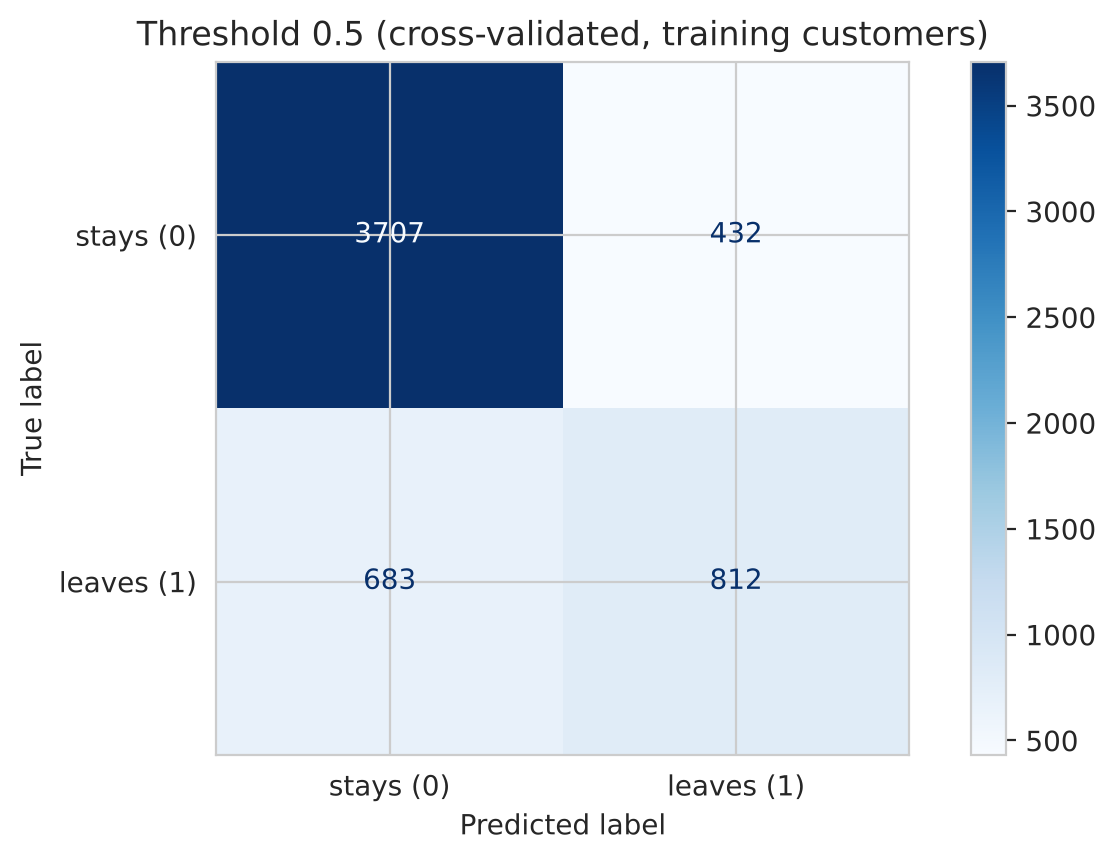

True negatives  (stayed, we said stays):  3707
False positives (stayed, we said leaves): 432   <- wasted calls
False negatives (left,   we said stays):  683   <- leavers we missed
True positives  (left,   we said leaves): 812
Precision = TP/(TP+FP) = 0.653 | Recall = TP/(TP+FN) = 0.543


In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score, f1_score, accuracy_score
pred = (proba >= 0.5).astype(int)
ConfusionMatrixDisplay(confusion_matrix(y_train, pred), display_labels=['stays (0)', 'leaves (1)']).plot(cmap='Blues', values_format='d')
plt.title('Threshold 0.5 (cross-validated, training customers)'); plt.show()
tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
print(f'True negatives  (stayed, we said stays):  {tn}')
print(f'False positives (stayed, we said leaves): {fp}   <- wasted calls')
print(f'False negatives (left,   we said stays):  {fn}   <- leavers we missed')
print(f'True positives  (left,   we said leaves): {tp}')
print(f'Precision = TP/(TP+FP) = {tp/(tp+fp):.3f} | Recall = TP/(TP+FN) = {tp/(tp+fn):.3f}')

Read it like a manager: we **missed** about 680 leavers (false negatives) and wasted about 430 calls (false positives). Which mistake is worse? For churn, missing a leaver usually costs more than a wasted call.

### 16c · The precision–recall trade-off: moving the threshold

In [16]:
rows = []
for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    p = (proba >= t).astype(int)
    rows.append({'threshold': t, 'customers flagged': p.sum(), 'precision': precision_score(y_train, p),
                 'recall': recall_score(y_train, p), 'f1': f1_score(y_train, p), 'accuracy': accuracy_score(y_train, p)})
pd.DataFrame(rows).round(3)

,threshold,customers flagged,precision,recall,f1,accuracy
0,0.2,2688,0.475,0.854,0.611,0.711
1,0.3,2120,0.541,0.767,0.634,0.765
2,0.4,1672,0.594,0.664,0.627,0.790
3,0.5,1244,0.653,0.543,0.593,0.802
4,0.6,834,0.711,0.397,0.509,0.797
5,0.7,404,0.782,0.211,0.333,0.775


**Lower threshold → flag more customers → recall goes up, precision goes down.** There is no free lunch: you choose the balance. Notice that F1 is best around 0.3–0.4, not at the default 0.5.

### 16d · ROC and precision–recall curves: all thresholds at once

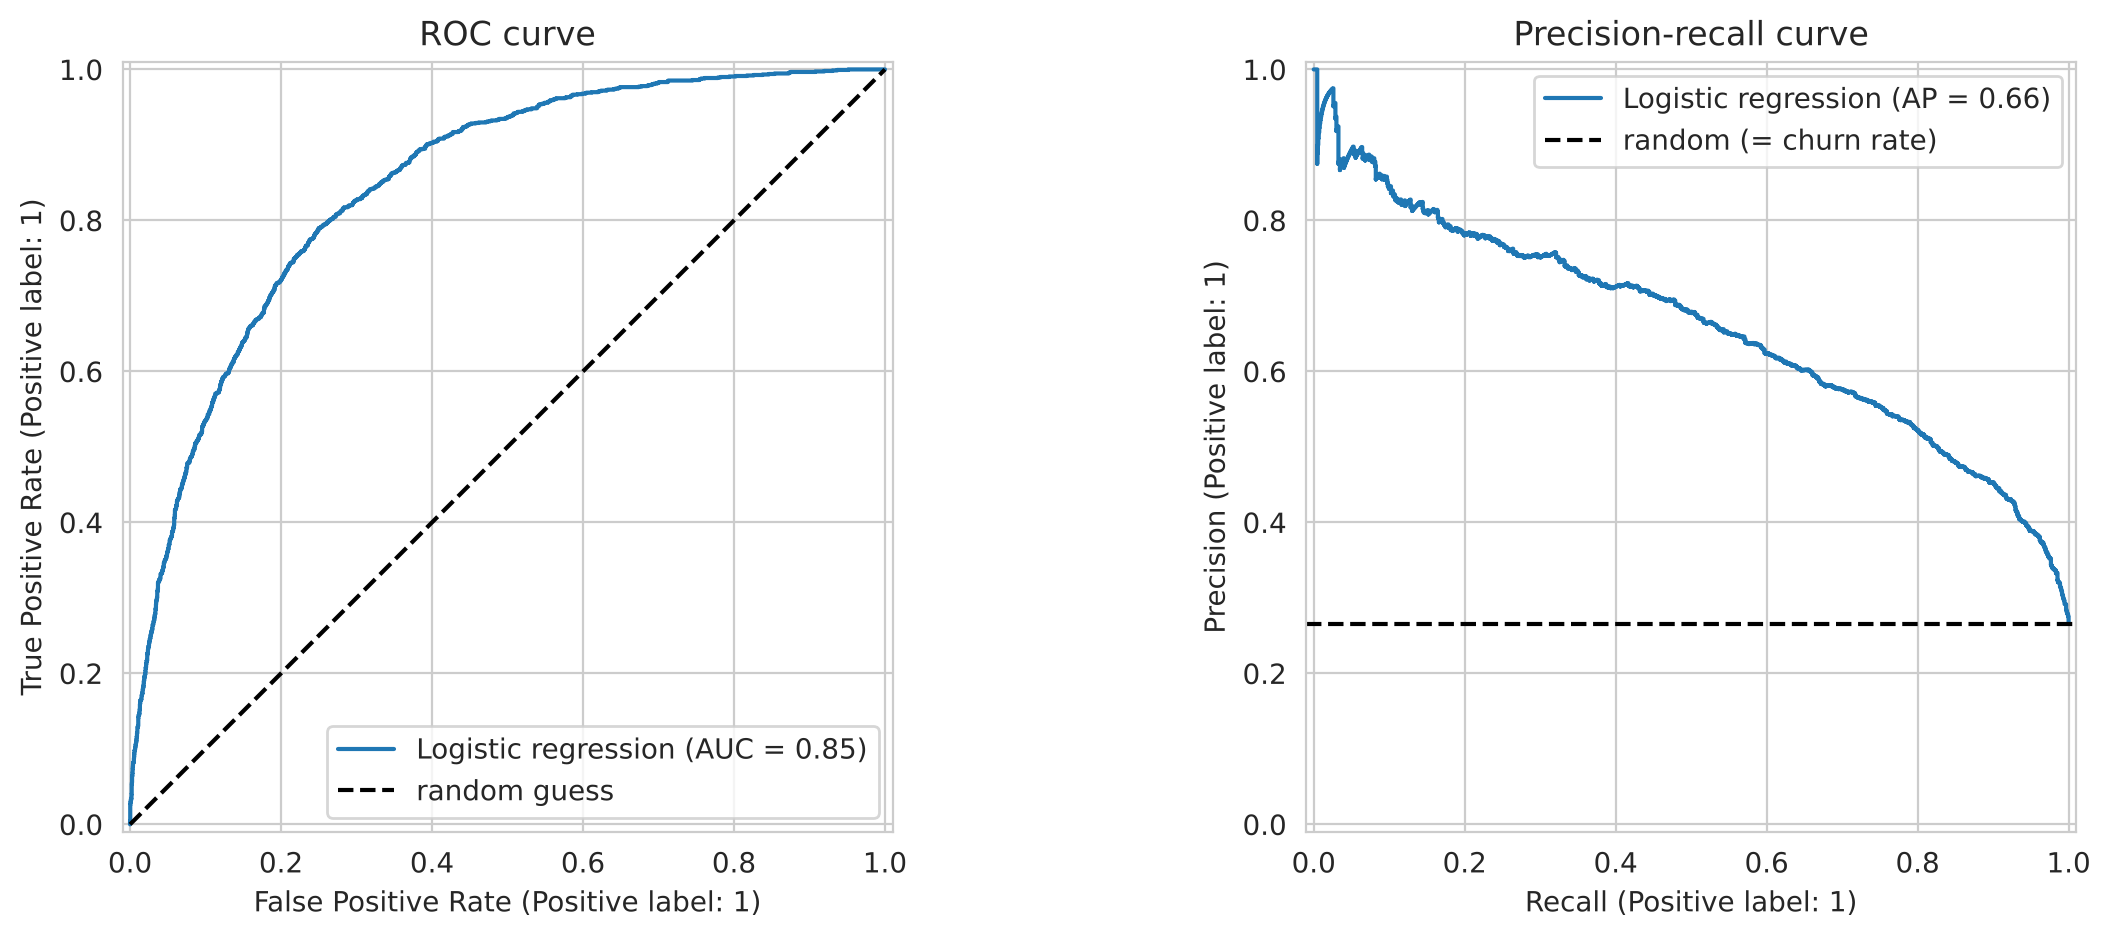

ROC AUC: 0.846


In [17]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay, roc_auc_score
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
RocCurveDisplay.from_predictions(y_train, proba, ax=ax[0], name='Logistic regression')
ax[0].plot([0, 1], [0, 1], 'k--', label='random guess'); ax[0].legend(); ax[0].set_title('ROC curve')
PrecisionRecallDisplay.from_predictions(y_train, proba, ax=ax[1], name='Logistic regression')
ax[1].axhline(y_train.mean(), color='k', ls='--', label='random (= churn rate)'); ax[1].legend(); ax[1].set_title('Precision-recall curve')
plt.show()
print('ROC AUC:', round(roc_auc_score(y_train, proba), 3))

- **ROC curve:** each point is one threshold; the closer the curve hugs the top-left corner, the better. **AUC** = area under it: the chance a random leaver gets a higher score than a random stayer.
- **Precision–recall curve:** the honest view when the positive class is rare. Random guessing gives a flat line at the churn rate (0.265).

### 16e · Choosing the threshold with money
Suppose (the business tells us): a call + discount costs **\$100**; if we call a real leaver, **30%** stay; a kept customer is worth **\$1,500**. So calling a real leaver earns 0.30 × 1,500 − 100 = **+\$350**; calling a stayer costs **−\$100**.

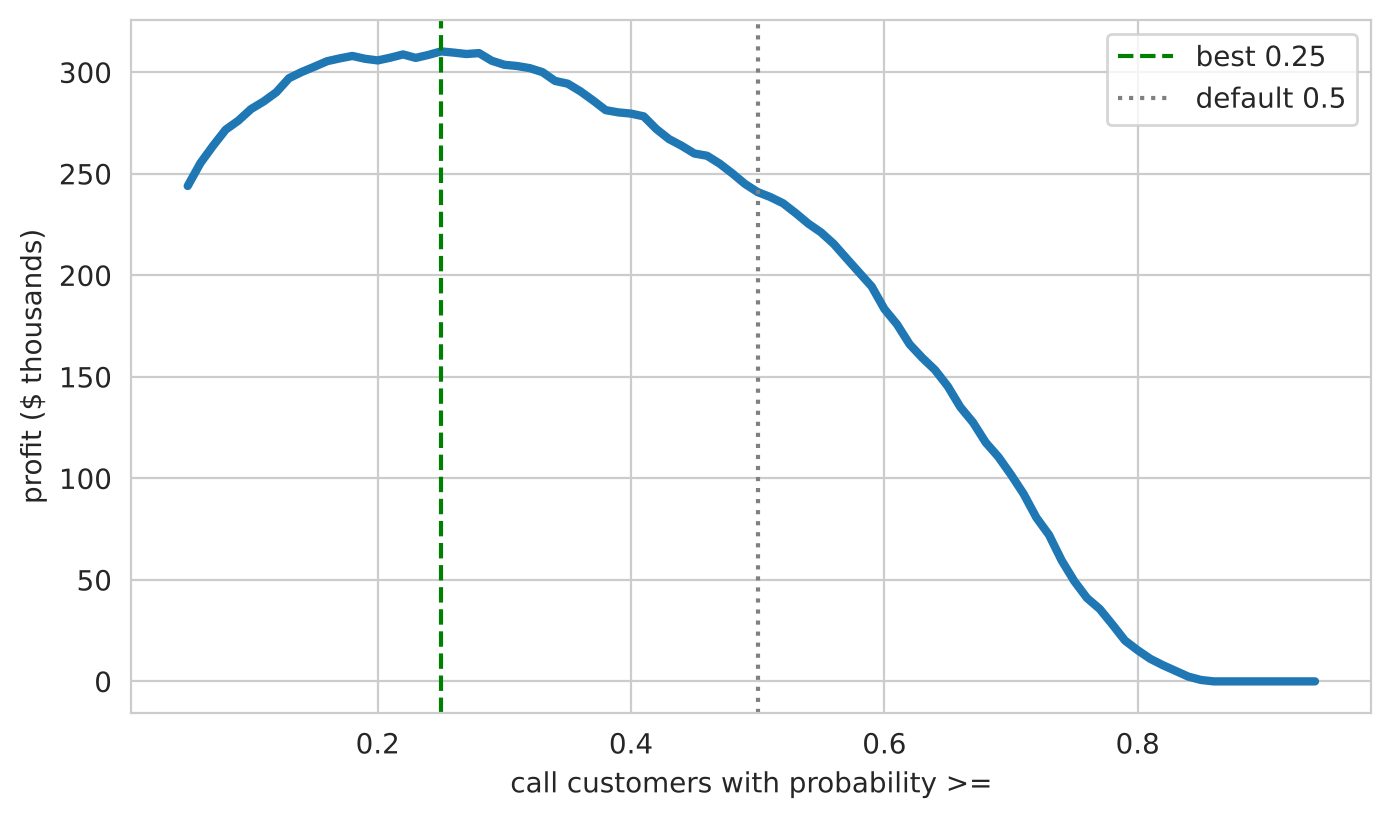

Best threshold 0.25: profit $310,300 | at 0.5: $241,000 | call everyone: $109,350


In [18]:
def profit(threshold):
    called = proba >= threshold
    return (called & (y_train.values == 1)).sum() * 0.30 * 1500 - called.sum() * 100

ts = np.arange(0.05, 0.95, 0.01)
ps = [profit(t) for t in ts]
best = ts[int(np.argmax(ps))]
plt.plot(ts, np.array(ps) / 1000, linewidth=3); plt.axvline(best, color='green', ls='--', label=f'best {best:.2f}'); plt.axvline(0.5, color='grey', ls=':', label='default 0.5')
plt.xlabel('call customers with probability >='); plt.ylabel('profit ($ thousands)'); plt.legend(); plt.show()
print(f'Best threshold {best:.2f}: profit ${max(ps):,.0f} | at 0.5: ${profit(0.5):,.0f} | call everyone: ${profit(0):,.0f}')

The best threshold is about **0.25**, far below 0.5, and earns about **30% more** (\$310k vs \$241k). Shortcut: call when probability × 0.30 × 1,500 > 100, i.e. probability > 100 / 450 ≈ **0.22**: very close to what the search found. This formula only works if the probabilities are trustworthy (calibrated, Part 5).

## Step 17 · Handling imbalance: `class_weight='balanced'`
A popular option makes the model pay more attention to the rare class. Compare at the default threshold:

In [19]:
balanced = Pipeline([('preprocess', preprocess), ('model', LogisticRegression(max_iter=2000, class_weight='balanced'))])
evaluate('Logistic regression, class_weight=balanced', balanced)

,accuracy,precision,recall,f1,roc_auc
"Baseline: always ""stays""",0.735,0.000,0.000,0.000,0.500
Logistic regression,0.802,0.653,0.543,0.592,0.846
"Logistic regression, class_weight=balanced",0.748,0.517,0.801,0.628,0.846


Recall jumps (~0.80) and precision drops: at the default 0.5 threshold it behaves much like a lower threshold. The ranking quality (ROC AUC) is almost the same. Its probabilities, however, are **inflated** (it predicts leaving too often), so for money calculations prefer the plain model plus a chosen threshold.

## Step 18 · Tune the regularisation strength C
In scikit-learn's logistic regression, **C** is the *inverse* of regularisation: small C = strong penalty.

In [20]:
from sklearn.model_selection import GridSearchCV
search = GridSearchCV(logreg, {'model__C': [0.01, 0.1, 1, 10]}, cv=folds, scoring='roc_auc').fit(X_train, y_train)
print('Best C:', search.best_params_['model__C'], '| CV ROC AUC:', round(search.best_score_, 4))
pd.DataFrame({'C': [str(c) for c in search.cv_results_['param_model__C']], 'CV ROC AUC': search.cv_results_['mean_test_score'].round(4)})

Best C: 10 | CV ROC AUC: 0.8464


,C,CV ROC AUC
0,0.01,0.8435
1,0.1,0.8455
2,1.0,0.8462
3,10.0,0.8464


All values of C give nearly the same AUC (0.844–0.846): with 45 columns and 5,600 customers the model isn't overfitting, so the penalty barely matters.

## Step 16f · Reading the model: which features push towards leaving?

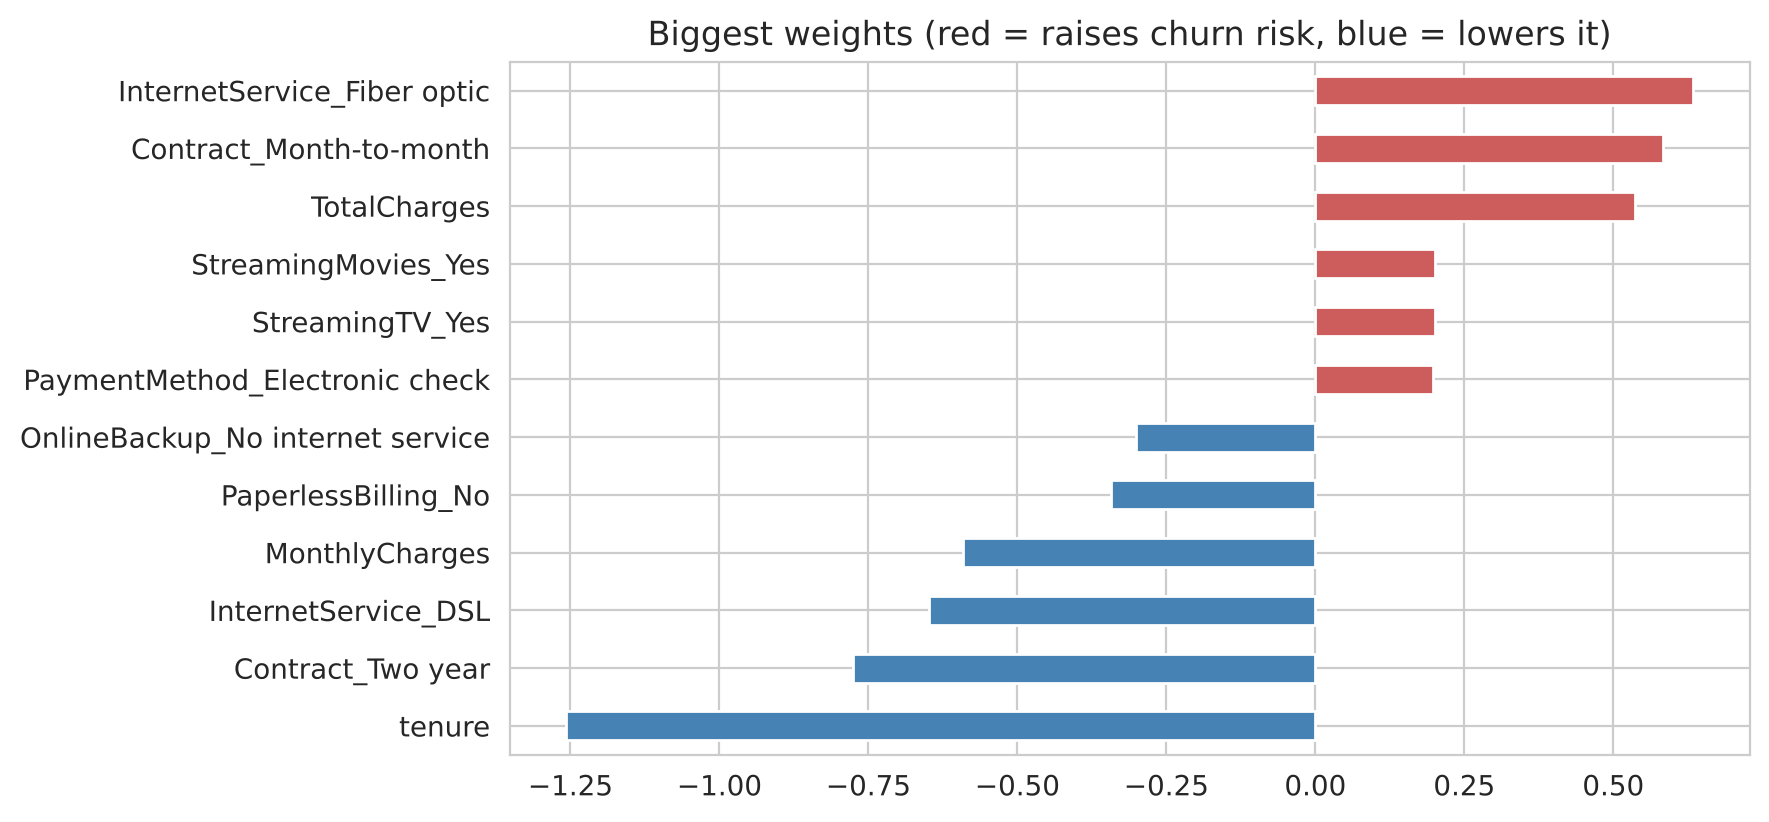

In [21]:
logreg.fit(X_train, y_train)
names = [n.split('__')[1] for n in logreg.named_steps['preprocess'].get_feature_names_out()]
coef = pd.Series(logreg.named_steps['model'].coef_[0], index=names).sort_values()
pd.concat([coef.head(6), coef.tail(6)]).plot.barh(color=['steelblue'] * 6 + ['indianred'] * 6)
plt.title('Biggest weights (red = raises churn risk, blue = lowers it)'); plt.show()

Positive weights (red) push the probability **up**: month-to-month contract, fiber, electronic check. Negative weights (blue) push it **down**: long tenure, two-year contract. Each weight changes the **log-odds** (Part 5): e^weight is how much the **odds** of leaving are multiplied.

*(Tenure has a strong negative weight while TotalCharges has a positive one: the two columns are closely related, so read related weights together, not one by one.)*

## Step 19 · Final test, once
We keep the plain logistic regression (C = 1) and the threshold chosen on training data (0.25). Now we open the test set.

Threshold 0.25
Test ROC AUC: 0.842
              precision    recall  f1-score   support

       stays      0.911     0.704     0.795      1035
      leaves      0.498     0.810     0.616       374

    accuracy                          0.732      1409
   macro avg      0.704     0.757     0.706      1409
weighted avg      0.801     0.732     0.747      1409



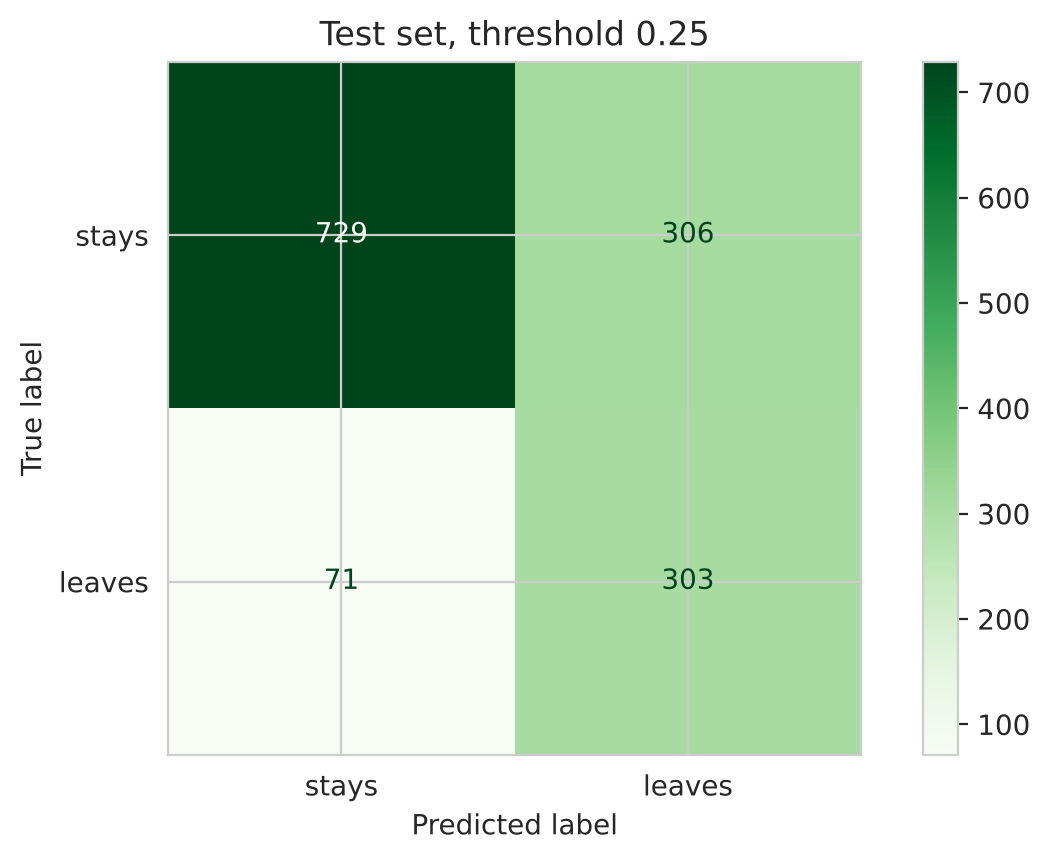

In [22]:
from sklearn.metrics import classification_report
THRESHOLD = round(best, 2)
test_proba = logreg.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= THRESHOLD).astype(int)
print(f'Threshold {THRESHOLD}')
print('Test ROC AUC:', round(roc_auc_score(y_test, test_proba), 3))
print(classification_report(y_test, test_pred, target_names=['stays', 'leaves'], digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_test, test_pred), display_labels=['stays', 'leaves']).plot(cmap='Greens', values_format='d')
plt.title(f'Test set, threshold {THRESHOLD}'); plt.show()

On 1,409 new customers: we now catch most leavers (high recall), at the price of more wasted calls (lower precision). That is a deliberate business choice: a missed leaver costs more than a wasted call.

## Step 20 · Save the model and score new customers

In [23]:
import joblib, json
joblib.dump(logreg, 'churn_model.joblib')
json.dump({'threshold': THRESHOLD}, open('churn_threshold.json', 'w'))

model = joblib.load('churn_model.joblib')
threshold = json.load(open('churn_threshold.json'))['threshold']
new = X_test.head(5).copy()
new['probability_of_leaving'] = model.predict_proba(new)[:, 1].round(3)
new['call_them'] = new['probability_of_leaving'] >= threshold
new[['tenure', 'Contract', 'InternetService', 'MonthlyCharges', 'probability_of_leaving', 'call_them']]

,tenure,Contract,InternetService,MonthlyCharges,probability_of_leaving,call_them
437,72,Two year,Fiber optic,114.05,0.046,False
2280,8,Month-to-month,Fiber optic,100.15,0.684,True
2235,41,One year,DSL,78.35,0.059,False
4460,18,Month-to-month,Fiber optic,78.20,0.402,True
3761,72,Two year,DSL,82.65,0.021,False


## Summary
| Step | What we learned |
|---|---|
| 4 | investigate odd types: blank TotalCharges = new customers → 0 |
| 3, 6 | imbalanced target → stratified split, and distrust accuracy |
| 13 | "always stays" = 73.5% accuracy, 0 recall |
| 15–16 | logistic regression gives probabilities; ROC AUC ≈ 0.85 |
| 16b–c | confusion matrix; lower threshold = more recall, less precision |
| 16e | the best threshold comes from the business cost (≈ 0.25, not 0.5) |
| 17 | class_weight raises recall but distorts probabilities |
| 19 | the test set confirms the result |

## Exercises
1. Change the business numbers (call cost \$50, success rate 20%). Predict the new threshold with the formula, then check with the profit curve.
2. Which threshold gives the best F1? Is it the same as the most profitable one? Why not?
3. Remove `gender`. Does ROC AUC change? What does that tell you?